# Week 1, Part 03: Exploratory Data Analysis and Visualization

<sub>[Previous: Data Exploration: Provenance, Shape, and Quality](week1_02_exploration.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

This is notebook 03. I tried to do the basic exploration but more can be done here. The order is the one I actually explore in: anchor on the outcome, look at who is in the data, hunt for sentinels and outliers, then move to bivariate questions, forming a hypothesis and testing it before believing it. Every number is computed live from the data.

### Contents

1. [How common is preterm birth?](#target)
2. [Who is in the data? (univariate)](#who)
3. [Hunting sentinels and outliers](#outliers)
4. [What predicts preterm? (bivariate)](#predict)
5. [The racial disparity, and a hypothesis test](#disparity)
6. [Does education close the gap?](#education)
7. [Exploring the COVID question](#covid)
8. [Correlations: significance vs effect size](#corr)
9. [EDA takeaways and the plan from here](#takeaways)

### Setup

A short, documented setup so the rest of the notebook reads cleanly. First the imports and display options. `scipy` is here because we run real hypothesis tests later, and we fix a random seed so every `df.sample()` below is reproducible.

In [1]:
# Setup. Week 1 is acquisition + exploration + EDA, so we load the RAW exploration table:
# the 17 pre-delivery birth-certificate fields we gathered, with their original values untouched.
# (No engineered features, no modeling columns yet. Those come in later weeks.) This table is built
# from the COMPLETE NBER public-use files for 2018-2024, restricted to singletons. Every number below
# is computed live from it. scipy is here for the hypothesis tests we run as we go, and we fix a seed
# so every df.sample() is reproducible.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
RNG = 7  # fixed seed so every df.sample() below is reproducible

Load the raw exploration table once. It holds the 17 pre-delivery certificate fields we gathered this week, built from the complete 2018-2024 public-use files (singletons only), plus readable label maps for the coded fields and the published national birth totals we will validate our counts against.

In [2]:
DATA = Path("..") / "data" / "interim" / "natality_exploration_2019_2024.parquet"
df = pd.read_parquet(DATA)  # ALL U.S. singleton births 2018-2024, raw pre-delivery fields only

# Human-readable label maps for the coded NCHS fields.
EDU = {1: "<8th grade", 2: "9-12, no diploma", 3: "HS grad/GED", 4: "Some college",
       5: "Associate", 6: "Bachelor", 7: "Master", 8: "Doctorate/Prof"}
PAY = {1: "Private", 2: "Medicaid", 3: "Self-pay", 4: "Indian Health Svc", 5: "CHAMPUS/TRICARE",
       6: "Other govt", 8: "Other"}
RACE_ORDER = ["NH White", "NH Asian", "Hispanic", "NH Multiracial", "NH NHOPI", "NH AIAN", "NH Black"]
# Published total U.S. births (NCHS final; 2024 provisional). Singletons are about 96.8% of births.
PUBLISHED_BIRTHS = {2018: 3791712, 2019: 3747540, 2020: 3613647, 2021: 3664292, 2022: 3667758,
                    2023: 3596017, 2024: 3600000}

A colorblind-safe palette (the Okabe-Ito set), reused on every figure so the series looks like one piece. We give the four largest race groups distinct colors and leave the rest grey to keep attention where the data are most reliable.

In [3]:
PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999",
           "ink": "#1a1a2e"}
RACE_COLOR = {r: PALETTE["grey"] for r in RACE_ORDER}
RACE_COLOR.update({"NH White": PALETTE["blue"], "NH Black": PALETTE["red"],
                   "Hispanic": PALETTE["green"], "NH Asian": PALETTE["orange"]})

Matplotlib house style, plus a tiny `style()` helper so every static figure gets a takeaway-as-title and labelled axes without repeating boilerplate.

In [4]:
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return ax

Marquee charts also get an interactive Plotly companion, so `ptmpl()` gives those figures the same dark-text, low-clutter house style.

In [5]:
pio.renderers.default = "notebook_connected"  # small files; interactive in Jupyter / nbviewer

def ptmpl(fig, title, xtitle, ytitle, height=440):
    fig.update_layout(
        title=dict(text=title, x=0.02, font=dict(size=16, color=PALETTE["ink"])),
        xaxis_title=xtitle, yaxis_title=ytitle, plot_bgcolor="white", paper_bgcolor="white",
        font=dict(family="Inter, system-ui, sans-serif", size=13, color=PALETTE["ink"]),
        margin=dict(l=60, r=30, t=60, b=50), height=height,
        legend=dict(orientation="h", yanchor="bottom", y=1.03, x=0, font=dict(color=PALETTE["ink"])))
    fig.update_xaxes(showgrid=False, linecolor="#cccccc")
    fig.update_yaxes(showgrid=True, gridcolor="#ECECEC", zeroline=False)
    return fig

Finally, the 2 helpers we lean on most. `rate_by()` returns the preterm rate and count for any grouping column, and it is the workhorse of the entire EDA. `risk_ratio_ci()` goes 1 step further for binary flags: it returns the risk ratio (flag=1 vs flag=0) with a 95% log-normal confidence interval, so we can report an effect size and its uncertainty together, not just a p-value. Both are worth reading once.

In [6]:
def rate_by(frame, col, dropna_target=True):
    """Preterm rate (%) and count for any grouping column. The workhorse of the whole EDA."""
    d = frame.dropna(subset=["preterm"]) if dropna_target else frame
    g = d.groupby(col)["preterm"].agg(rate="mean", n="size")
    g["rate"] = g["rate"] * 100
    return g

def risk_ratio_ci(frame, flag_col, target="preterm"):
    """Risk ratio (flag=1 vs flag=0) with a 95% log-normal CI. Returns (rr, lo, hi, r1, r0)."""
    d = frame.dropna(subset=[target, flag_col])
    g = d.groupby(flag_col)[target].agg(["mean", "sum", "size"])
    r1, r0 = g.loc[1.0, "mean"], g.loc[0.0, "mean"]
    a, n1 = g.loc[1.0, "sum"], g.loc[1.0, "size"]
    c, n0 = g.loc[0.0, "sum"], g.loc[0.0, "size"]
    rr = r1 / r0
    se = np.sqrt(1/a - 1/n1 + 1/c - 1/n0)
    return rr, rr*np.exp(-1.96*se), rr*np.exp(1.96*se), r1*100, r0*100

### First, a look at the raw material

Each notebook stands on its own, so we start the way a real analysis session does: load the table and look at a handful of actual rows. One record is one singleton birth.

In [7]:
df.sample(5, random_state=RNG)

,birth_year,mager,meduc,bmi,cig_0,priorlive,priordead,married,rf_pdiab,rf_phype,rf_ppterm,rf_cesar,wic,first_trimester_care,pay,mother_race_ethnicity,preterm
19117181,2023,26,6.0,26.600000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,Hispanic,0.0
19115281,2023,36,7.0,24.000000,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,NH White,0.0
24082594,2024,28,4.0,23.200001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,NH Multiracial,0.0
3195108,2018,30,3.0,25.700001,0.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,Hispanic,0.0
6895695,2019,30,6.0,19.000000,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,NH White,0.0


<a id="target"></a>
## How common is preterm birth?

We always anchor on the outcome first. Let me compute the overall rate and the per-year rate (rates, not counts, for the reason established in notebook 01).

In [8]:
print('Overall preterm rate: {:.2f}%'.format(df.preterm.mean()*100))
print('\nBy year (rates, because raw counts are not comparable across years):')
print(rate_by(df, 'birth_year').round(2))

Overall preterm rate: 8.57%

By year (rates, because raw counts are not comparable across years):


            rate        n
birth_year               
2018        8.23  3671603
2019        8.46  3631109
2020        8.41  3501693
2021        8.75  3549564
2022        8.66  3555590
2023        8.70  3489000
2024        8.75  3521848


About **8.6%** of singleton births are preterm, stable year to year. That number sits sensibly below the 10.4% all-births headline, exactly as expected once multiples are excluded, which is our first reassurance that the data is sound. That imbalance already tells us that accuracy will be a garbage metric when we model (a model that always says 'not preterm' scores 91%), so we will need to lean on rate-based and calibration metrics instead.

<a id="who"></a>
## Who is in the data? (univariate)

Before relating anything to the outcome, we want to know who these mothers are. A `describe` table is also our first outlier radar, so I watch the `max` column closely.

In [9]:
df[['mager','meduc','bmi','cig_0','priorlive','priordead']].describe().round(2).T[['mean','std','min','50%','max']]

,mean,std,min,50%,max
mager,29.32,5.81,12.0,29.0,50.0
meduc,4.41,1.75,1.0,4.0,8.0
bmi,29.15,12.56,13.0,26.4,99.9
cig_0,0.76,4.03,0.0,0.0,98.0
priorlive,1.11,1.31,0.0,1.0,23.0
priordead,0.01,0.18,0.0,0.0,25.0


Two things jump out of the `max` column immediately. `bmi` maxes at 99.9 and `cig_0` at 98. Those are not real measurements; they are NCHS 'not stated' sentinel codes masquerading as numbers, exactly the kind of thing the bias notes warned about. I will deal with them in the next section before they poison a single chart. For now, let me look at each genuine distribution on its own, one chart at a time.

**Maternal age.** I expect a roughly bell-shaped curve centered in the late twenties, with tails of teen and older mothers who carry different risk profiles.

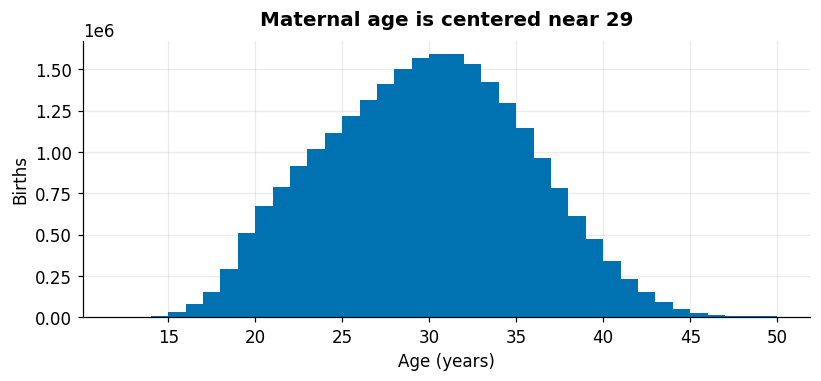

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(df['mager'].dropna(), bins=range(12, 51), color=PALETTE['blue'])
style(ax, 'Maternal age is centered near 29', 'Age (years)', 'Births')
plt.tight_layout(); plt.show()

**Maternal age against the outcome: a U-shape.** The age *distribution* is bell-shaped, but the preterm *rate* by age is not: obstetrically we expect both the youngest and the oldest mothers to carry higher risk, with a trough in the late twenties. Let me bracket age and read the rate in each bracket to see whether that U-shape actually shows up here.

Preterm rate (%) by maternal-age bracket (expect a U-shape):
  <20    9.59%
  20-24  8.43%
  25-29  7.94%
  30-34  8.08%
  35-39  9.56%
  40+    12.39%


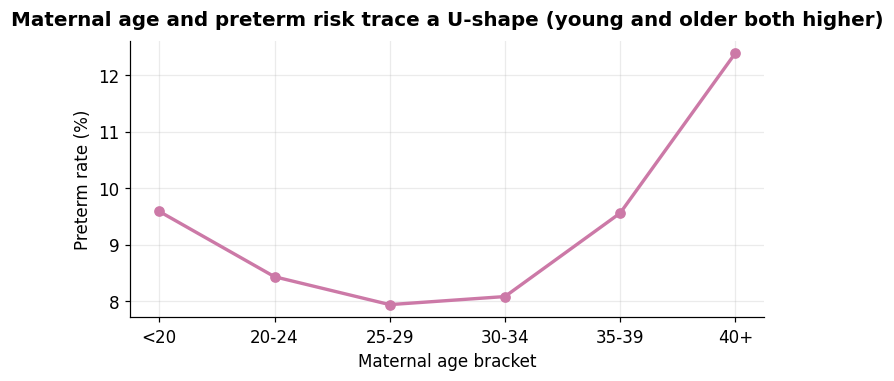

In [11]:
breaks = [20, 25, 30, 35, 40]
def age_bracket(a):
    for i, b in enumerate(breaks):
        if a < b: return i
    return len(breaks)
labels = ["<20","20-24","25-29","30-34","35-39","40+"]
ab = df.dropna(subset=['preterm','mager']).assign(ab=lambda x: x['mager'].map(age_bracket))
ag = ab.groupby('ab')['preterm'].mean().mul(100)
print("Preterm rate (%) by maternal-age bracket (expect a U-shape):")
for i, lab in enumerate(labels):
    if i in ag.index: print(f"  {lab:<6} {ag.loc[i]:.2f}%")
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot([labels[i] for i in ag.index], ag.values, marker='o', color=PALETTE['purple'], linewidth=2.2)
style(ax, 'Maternal age and preterm risk trace a U-shape (young and older both higher)',
      'Maternal age bracket', 'Preterm rate (%)')
plt.tight_layout(); plt.show()

The U-shape is there: the rate is elevated for the youngest mothers, drops to its lowest in the 25 to 29 bracket, then climbs steeply again after 35. That non-monotone shape is the reason the modeling weeks (PLANNED) intend to *bracket* age rather than fit it as a single linear term, since a straight line through a U would wash out both tails and misstate the risk at the extremes.

**Pre-pregnancy BMI.** Here I deliberately filter out the values above 70, because the 99.9 sentinel would otherwise stretch the axis and hide the real shape. What remains should be right-skewed with a genuine obesity tail.

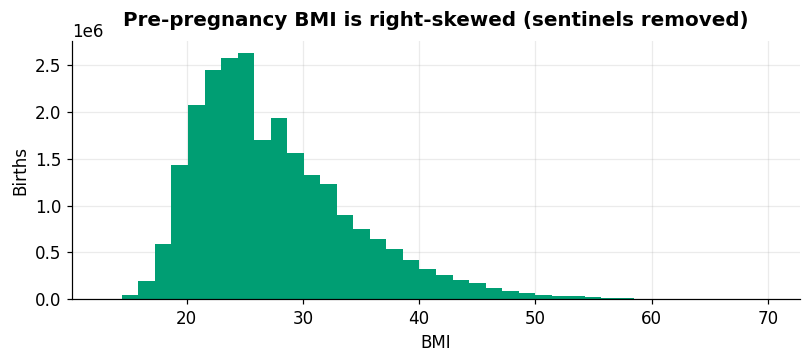

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(df['bmi'][df['bmi'] < 70].dropna(), bins=40, color=PALETTE['green'])
style(ax, 'Pre-pregnancy BMI is right-skewed (sentinels removed)', 'BMI', 'Births')
plt.tight_layout(); plt.show()

**Maternal education and payment source.** Two coded fields mapped to readable labels. Education should pile up at high-school-graduate and bachelor levels; payment tells us how much of this population is on Medicaid, which matters because payment is one of our SES proxies.

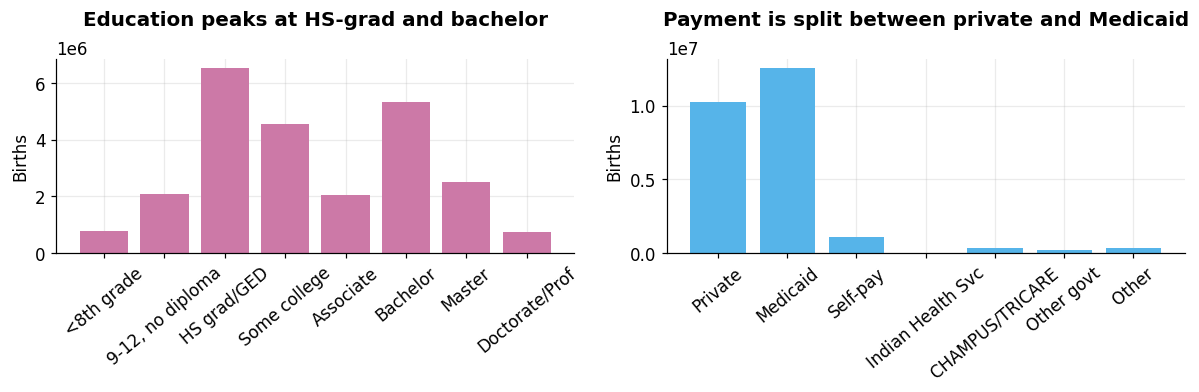

In [13]:
ed = df['meduc'].dropna().astype(int).value_counts().sort_index()
pa = df['pay'].dropna().astype(int).value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar([EDU[i] for i in ed.index], ed.values, color=PALETTE['purple'])
style(axes[0], 'Education peaks at HS-grad and bachelor', '', 'Births')
axes[0].tick_params(axis='x', rotation=40)
axes[1].bar([PAY.get(i, str(i)) for i in pa.index], pa.values, color=PALETTE['sky'])
style(axes[1], 'Payment is split between private and Medicaid', '', 'Births')
axes[1].tick_params(axis='x', rotation=40); plt.tight_layout(); plt.show()

All as expected: age is bell-shaped, BMI is right-skewed with a real obesity tail, education piles up where the population does, and payment is dominated by private and Medicaid. Nothing preterm-specific yet; this is just the cast of characters. Now let me deal with those sentinels properly.

<a id="outliers"></a>
## Hunting sentinels and outliers

Instead of eyeballing, let me count the sentinels and the implausible tails. A value being rare is fine; a value being *impossible* is a data-quality flag that needs a decision.

In [14]:
print(f"BMI >= 70 (sentinel/implausible): {int((df.bmi>=70).sum()):>6,}  ({(df.bmi>=70).mean()*100:.2f}%)")
print(f"cig_0 >= 90 (sentinel codes)    : {int((df.cig_0>=90).sum()):>6,}  ({(df.cig_0>=90).mean()*100:.2f}%)")
print(f"Maternal age <= 15              : {int((df.mager<=15).sum()):>6,}")
print(f"Maternal age >= 45              : {int((df.mager>=45).sum()):>6,}")
print(f"Prior live births >= 10         : {int((df.priorlive>=10).sum()):>6,}")

BMI >= 70 (sentinel/implausible): 545,712  (2.19%)
cig_0 >= 90 (sentinel codes)    :  5,135  (0.02%)
Maternal age <= 15              : 44,093
Maternal age >= 45              : 63,703


Prior live births >= 10         : 21,491


The BMI and cigarette sentinels are small in share but would badly distort a mean or a histogram axis, so we exclude them from anything quantitative this week and flag that the feature pipeline will need to null them per-field upstream. The age and parity extremes are *plausible*: a 13-year-old mother, a 49-year-old mother, a mother with 12 prior births genuinely exist, and they are clinically high-risk, so we keep them. The discipline is telling a sentinel (drop) apart from a rare-but-real value (keep), and saying which is which.

<a id="predict"></a>
## What predicts preterm? (bivariate)

Now the question that matters. The approach is the same for each candidate predictor: use `rate_by()` to compute the preterm rate within each level, then let the gradient speak. We take the signals we expect to matter most, one at a time.

**Prior preterm birth.** Clinically this is the single strongest known risk factor, so it is our first sanity check. If the data are sound, a mother with a prior preterm birth should have a much higher rate.

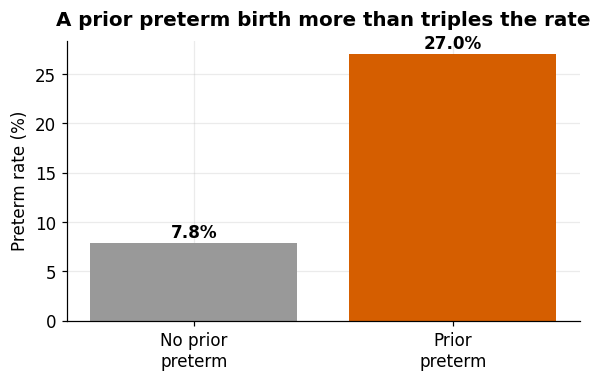

Risk ratio: 3.45x  (27.0% vs 7.8%)


In [15]:
pp = rate_by(df, 'rf_ppterm')
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(['No prior\npreterm', 'Prior\npreterm'], pp['rate'].values, color=[PALETTE['grey'], PALETTE['red']])
for i, v in enumerate(pp['rate'].values): ax.text(i, v+0.6, f'{v:.1f}%', ha='center', fontweight='bold')
style(ax, 'A prior preterm birth more than triples the rate', '', 'Preterm rate (%)')
plt.tight_layout(); plt.show()
print(f"Risk ratio: {pp.loc[1.0,'rate']/pp.loc[0.0,'rate']:.2f}x  ({pp.loc[1.0,'rate']:.1f}% vs {pp.loc[0.0,'rate']:.1f}%)")

A risk ratio on its own is a point estimate; the honest quantity is the ratio *with* a confidence interval, which puts the effect size and its uncertainty side by side. Let me attach a 95% CI to the prior-preterm risk ratio using the `risk_ratio_ci()` helper. If the interval excludes 1, the association is not noise, and here we also want to see that the effect is large, not merely significant.

In [16]:
rr, lo, hi, r1, r0 = risk_ratio_ci(df, 'rf_ppterm')
print(f"Prior preterm birth: {r1:.1f}% vs {r0:.1f}%  ->  risk ratio {rr:.2f} "
      f"(95% CI {lo:.2f} to {hi:.2f}). The CI excludes 1, and the effect is large, not just significant.")

Prior preterm birth: 27.0% vs 7.8%  ->  risk ratio 3.45 (95% CI 3.43 to 3.46). The CI excludes 1, and the effect is large, not just significant.


**An exploratory composite: medical-risk count.** I want to test an idea: sum the four pre-pregnancy risk flags into a 0-to-4 count and see if a real dose-response appears (more flags, higher rate). If it does, that is a feature worth engineering properly later; if it is flat, the idea is not worth pursuing. This is exploration, computed live, not a committed feature.

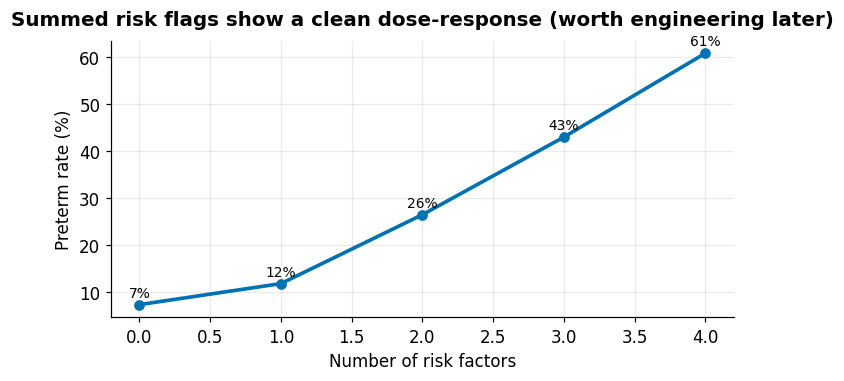

In [17]:
risk_n = df[['rf_pdiab','rf_phype','rf_ppterm','rf_cesar']].sum(axis=1)
mr = rate_by(df.assign(risk_n=risk_n), 'risk_n')
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(mr.index, mr['rate'].values, marker='o', color=PALETTE['blue'], linewidth=2.4)
for x, y in zip(mr.index, mr['rate'].values): ax.text(x, y+1.6, f'{y:.0f}%', ha='center', fontsize=9)
style(ax, 'Summed risk flags show a clean dose-response (worth engineering later)', 'Number of risk factors', 'Preterm rate (%)')
plt.tight_layout(); plt.show()

**Pre-pregnancy smoking.** A behavioral exposure. We define a smoker as 1 to 89 cigarettes per day, deliberately excluding the 98/99 sentinel codes found earlier so they do not contaminate the comparison.

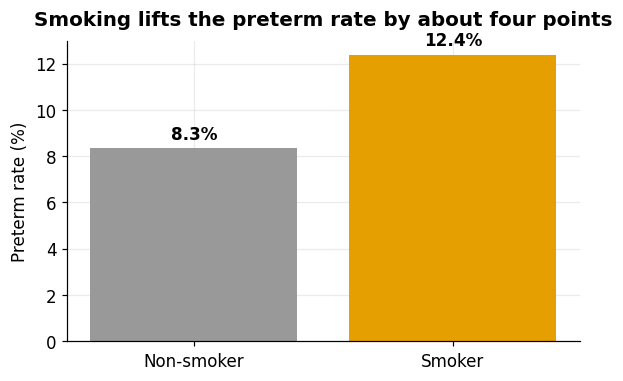

In [18]:
sm = rate_by(df.assign(smoker=np.where(df.cig_0.between(1,89), 'Smoker', 'Non-smoker')), 'smoker')
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(sm.index, sm['rate'].values, color=[PALETTE['grey'], PALETTE['orange']])
for i, v in enumerate(sm['rate'].values): ax.text(i, v+0.4, f'{v:.1f}%', ha='center', fontweight='bold')
style(ax, 'Smoking lifts the preterm rate by about four points', '', 'Preterm rate (%)')
plt.tight_layout(); plt.show()

Same discipline as prior preterm: report the smoking effect as a risk ratio with a 95% CI, so the effect size sits beside the significance. I define a smoker flag of 1 for 1 to 89 cigarettes per day and 0 for exactly 0, dropping the sentinel/unknown codes so they do not contaminate the comparison.

In [19]:
sm = df.assign(smoker=np.where(df.cig_0.between(1,89), 1.0, np.where(df.cig_0==0, 0.0, np.nan)))
rr, lo, hi, r1, r0 = risk_ratio_ci(sm, 'smoker')
print(f"Pre-pregnancy smoking: {r1:.1f}% vs {r0:.1f}%  ->  risk ratio {rr:.2f} (95% CI {lo:.2f} to {hi:.2f}).")

Pre-pregnancy smoking: 12.4% vs 8.3%  ->  risk ratio 1.49 (95% CI 1.48 to 1.50).


**The strongest real signals are clinical.** A prior preterm birth more than triples the rate (about a 3.4x risk ratio), the summed risk count shows the clean dose-response we hoped for (climbing toward about 61% at four flags), and smoking adds about 4 points. These are exactly the kind of legitimate pre-delivery predictors we would want a model to lean on. But the thing to keep noting is that every one of these is a *group-level* gradient, not a clean individual separator. That tension comes back hard in the correlation section.

<a id="disparity"></a>
## The racial disparity, and a hypothesis test

Here is the central equity question. I refuse to just eyeball it: a roughly 4.7-point gap could in principle be sampling noise, so we state a null hypothesis and test it. **H0:** NH Black and NH White mothers have the same singleton preterm rate. First, plot the rates so we can see the ordering. This is the project's headline chart, so it gets the interactive Plotly treatment: hover any bar for its exact rate and group size.

In [20]:
rr = rate_by(df, 'mother_race_ethnicity').reindex(RACE_ORDER).dropna().sort_values('rate')
print('Per-race singleton preterm rate (%) and group size (values behind the bars):')
for grp, row in rr.iterrows():
    print(f"  {grp:<15} {row['rate']:.2f}%   (n = {int(row['n']):,})")
fig = go.Figure(go.Bar(
    x=rr['rate'].values, y=rr.index, orientation='h',
    marker_color=[RACE_COLOR[r] for r in rr.index],
    text=[f'{v:.1f}%' for v in rr['rate'].values], textposition='outside',
    customdata=rr['n'].values,
    hovertemplate='%{y}: %{x:.2f}% preterm  (n = %{customdata:,})<extra></extra>'))
fig.update_xaxes(range=[0, rr['rate'].max()*1.15])
ptmpl(fig, 'NH Black mothers have the highest singleton preterm rate',
      'Preterm rate (%)', '', height=420)
fig.show()

Per-race singleton preterm rate (%) and group size (values behind the bars):
  NH White        7.54%   (n = 12,575,254)
  NH Asian        7.58%   (n = 1,535,378)
  Hispanic        8.64%   (n = 6,274,954)
  NH Multiracial  8.95%   (n = 587,517)
  NH AIAN         10.68%   (n = 179,698)
  NH NHOPI        10.80%   (n = 67,182)
  NH Black        12.28%   (n = 3,471,014)


There is a roughly 4.7-point gap between NH Black and NH White mothers. But a difference on a dataset, however striking, deserves a test rather than a glance, so we run a two-proportion z-test. I compute it by hand so every step is visible (pooled proportion, standard error, z, two-sided p).

In [21]:
d = df.dropna(subset=['preterm'])
b = d[d.mother_race_ethnicity=='NH Black'].preterm
w = d[d.mother_race_ethnicity=='NH White'].preterm
p_pool = (b.sum() + w.sum()) / (len(b) + len(w))
se = np.sqrt(p_pool * (1 - p_pool) * (1/len(b) + 1/len(w)))
z = (b.mean() - w.mean()) / se
pval = 2 * (1 - stats.norm.cdf(abs(z)))
print(f'NH Black {b.mean()*100:.2f}% vs NH White {w.mean()*100:.2f}%  (gap {(b.mean()-w.mean())*100:.2f} pp)')
print(f'Two-proportion z = {z:.1f}, p = {pval:.1e}  =>  reject H0 overwhelmingly')

NH Black 12.28% vs NH White 7.54%  (gap 4.74 pp)
Two-proportion z = 279.3, p = 0.0e+00  =>  reject H0 overwhelmingly


The z came out around **280** (it is that large mostly because the full national data gives millions of mothers per group, which shrinks the standard error to almost nothing, so the substantive number is the 4.7-point gap, not the z itself). Either way, the p-value is very close to zero. That gap is not noise or just by chance. We keep the bias caveat from notebook 02 in mind: the NH AIAN and NH NHOPI bars rest on small samples and known misclassification, so we trust the Black, White, Hispanic, and Asian estimates most. And the framing that governs the whole project: **race is a marker of exposure to racism and structural barriers, not a biological cause** of preterm birth.

<a id="education"></a>
## Does education close the gap?

My honest first reaction was the same one most people have: this is probably really a socioeconomic gap, and it would close if we compared mothers of the same education. That is a falsifiable hypothesis, so let me try to falsify it by stratifying on education and drawing one line per race. If it is right, the NH Black and NH White lines should converge as education rises.

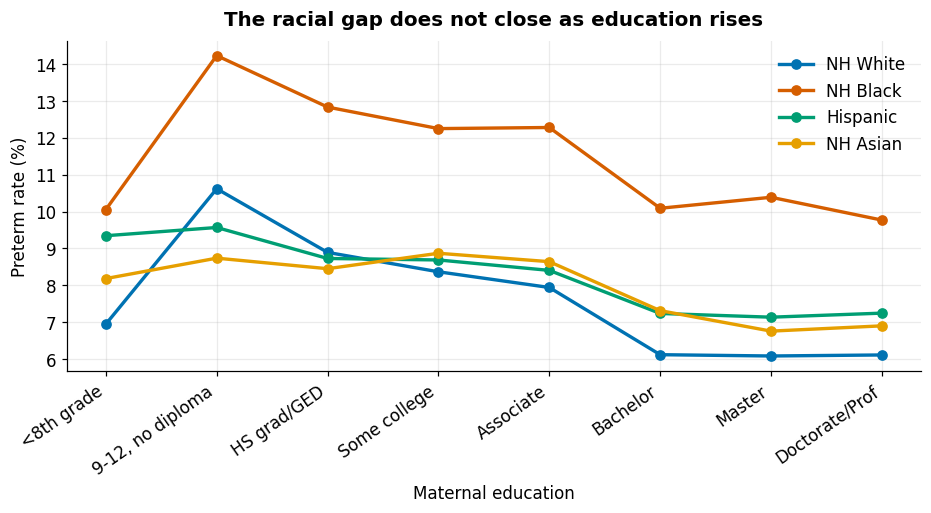

In [22]:
races = ['NH White', 'NH Black', 'Hispanic', 'NH Asian']
piv = (d[d.mother_race_ethnicity.isin(races)].dropna(subset=['meduc'])
        .assign(meduc=lambda x: x.meduc.astype(int))
        .groupby(['mother_race_ethnicity', 'meduc']).preterm.mean() * 100)
fig, ax = plt.subplots()
for race in races:
    s = piv[race].sort_index()
    ax.plot([EDU[i] for i in s.index], s.values, marker='o', color=RACE_COLOR[race], linewidth=2.2, label=race)
style(ax, 'The racial gap does not close as education rises', 'Maternal education', 'Preterm rate (%)')
plt.xticks(rotation=35, ha='right'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

The lines do not converge. To make the point impossible to miss, let me compute the single starkest comparison: the rate for the *most* educated Black mothers (bachelor or higher) against the *least* educated White mothers (high school or less).

In [23]:
bc = d[(d.mother_race_ethnicity=='NH Black') & (d.meduc>=6)].preterm.mean()*100
wl = d[(d.mother_race_ethnicity=='NH White') & (d.meduc<=3)].preterm.mean()*100
print(f'College-educated NH Black: {bc:.1f}%   vs   HS-or-less NH White: {wl:.1f}%')

College-educated NH Black: 10.2%   vs   HS-or-less NH White: 9.1%


**The hypothesis is falsified, and that is the finding.** Every NH Black line sits above every NH White line, and a college-educated NH Black mother has a *higher* preterm rate than a NH White mother who never finished high school. Education, the supposed great equalizer, does not equalize this. That points beyond a simple socioeconomic explanation, toward something structural that a birth certificate does not record. It is a strong, real pattern, and it is the thread we most want to pull on in the coming weeks.

**A second, independent falsification: payment source.** Education is 1 socioeconomic proxy; insurance payer is another, since private coverage versus Medicaid is a rough marker of income and access. If the disparity were purely a socioeconomic artifact, then comparing mothers on the *same* payer should erase the racial gap. Let me hold the payer fixed and compare *across race within that payer*. The test is: at a single payer, does the NH Black rate still sit above the NH White rate?

In [24]:
races = ['NH White', 'NH Black', 'Hispanic', 'NH Asian']
d = df.dropna(subset=['preterm'])
pv = (d[d.mother_race_ethnicity.isin(races)].dropna(subset=['pay'])
        .assign(pay=lambda x: x.pay.astype(int))
        .groupby(['mother_race_ethnicity','pay']).preterm.mean().mul(100))
print("Preterm rate (%) by race within payment source (Private=1, Medicaid=2):")
for r in races:
    s = pv[r]
    print(f"  {r:<12} private {s.get(1, float('nan')):.2f}%   Medicaid {s.get(2, float('nan')):.2f}%")
print("\nEvery NH Black cell exceeds the NH White cell at the SAME payer, so a single SES proxy does "
      "not close the gap, reinforcing the education result.")

Preterm rate (%) by race within payment source (Private=1, Medicaid=2):
  NH White     private 9.34%   Medicaid 6.90%
  NH Black     private 12.73%   Medicaid 11.38%
  Hispanic     private 8.92%   Medicaid 8.18%
  NH Asian     private 8.11%   Medicaid 7.47%

Every NH Black cell exceeds the NH White cell at the SAME payer, so a single SES proxy does not close the gap, reinforcing the education result.


The pattern holds across race within the same payer: NH Black mothers on private insurance have a higher preterm rate than NH White mothers on private insurance, and the same is true within Medicaid. Holding payer fixed does not close the gap, which is a second independent falsification of the pure-socioeconomic story, converging on the same conclusion as the education stratification. This stays associational, and the framing that governs the whole project holds: **race is a marker of exposure to racism and structural barriers, never a biological cause** of preterm birth.

<a id="covid"></a>
## Exploring the COVID question

With a 2018 to 2024 window we explored whether the pandemic moved preterm birth. Published work is genuinely mixed on this, which is itself the interesting part. National analyses found the annual picture [nuanced rather than dramatic](https://publications.aap.org/pediatrics/article/149/5/e2021055495/186706/), while CDC/NCHS reported the preterm rate [rose from 10.09% in 2020 to 10.49% in 2021](https://www.cdc.gov/nchs/products/databriefs/db442.htm) (an all-births figure). Separately, a [JAMA Pediatrics study documented a local decline](https://jamanetwork.com/journals/jamapediatrics/fullarticle/2777304) concentrated in a short spring-2020 window. Let me see whether our annual data shows any of it.

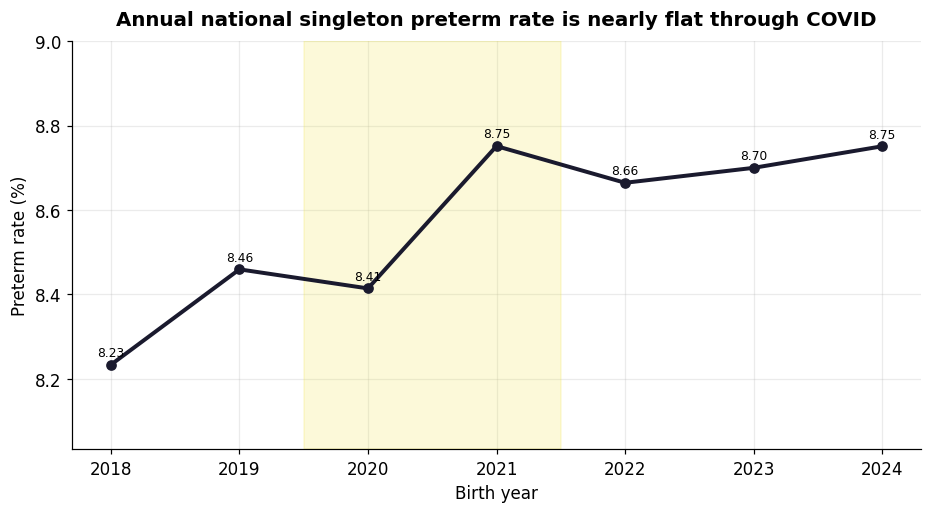

2019 -> 2020: -0.05 pp (small dip)   2020 -> 2021: +0.34 pp (rebound)


In [25]:
yr = rate_by(df, 'birth_year')
fig, ax = plt.subplots()
ax.axvspan(2019.5, 2021.5, color=PALETTE['yellow'], alpha=0.20)
ax.plot(yr.index, yr['rate'].values, marker='o', color=PALETTE['ink'], linewidth=2.6)
for x, y in zip(yr.index, yr['rate'].values): ax.text(x, y+0.02, f'{y:.2f}', ha='center', fontsize=8)
style(ax, 'Annual national singleton preterm rate is nearly flat through COVID', 'Birth year', 'Preterm rate (%)')
ax.set_ylim(yr['rate'].min()-0.2, yr['rate'].max()+0.25); plt.tight_layout(); plt.show()
v = yr['rate']
print(f'2019 -> 2020: {v[2020]-v[2019]:+.2f} pp (small dip)   2020 -> 2021: {v[2021]-v[2020]:+.2f} pp (rebound)')

Before drawing a lesson, let me split the COVID window by race, to check whether any group moved more than the national aggregate. If even the pandemic-era shift is small for the large, reliable groups, that tells us the annual national number is not hiding a big per-group swing.

In [26]:
covid = df[df.birth_year.isin([2019,2020,2021])].dropna(subset=['preterm'])
races = ['NH White','NH Black','Hispanic','NH Asian','NH AIAN','NH NHOPI']
print("COVID-era per-race annual preterm rate (%), 2019 -> 2020 -> 2021:")
for r in races:
    s = covid[covid.mother_race_ethnicity==r].groupby('birth_year')['preterm'].mean().mul(100)
    if {2019,2020,2021} <= set(s.index):
        print(f"  {r:<12} {s[2019]:.2f} -> {s[2020]:.2f} -> {s[2021]:.2f}  "
              f"(2020-2019 delta {s[2020]-s[2019]:+.2f} pp)")

COVID-era per-race annual preterm rate (%), 2019 -> 2020 -> 2021:


  NH White     7.44 -> 7.36 -> 7.69  (2020-2019 delta -0.08 pp)
  NH Black     12.12 -> 12.18 -> 12.51  (2020-2019 delta +0.06 pp)


  Hispanic     8.56 -> 8.51 -> 8.86  (2020-2019 delta -0.05 pp)
  NH Asian     7.32 -> 7.29 -> 7.90  (2020-2019 delta -0.03 pp)


  NH AIAN      10.27 -> 10.30 -> 10.88  (2020-2019 delta +0.04 pp)
  NH NHOPI     10.02 -> 10.63 -> 11.33  (2020-2019 delta +0.62 pp)


**The lesson is about temporal granularity.** The per-race deltas are small for the large, reliable groups (well under about 0.4 pp from 2019 to 2020), and only the smallest groups (NH AIAN, NH NHOPI) wiggle more, which is the small-cell noise we already flagged in notebook 02, not a signal. So the annual picture looks like 'no COVID effect.' But note what our data cannot do: the cleaned files carry no birth-month field, so a monthly curve is simply impossible here, and we deliberately fabricate no monthly numbers to fake one. The published local declines were concentrated in a short spring-2020 window, and averaging that into a yearly national aggregate dilutes it toward nothing. That is the whole point: a real effect at one time scale can vanish at another, so the granularity mismatch is the caution here, not a finding. The mixed published record backs this up: nuanced nationally ([AAP](https://publications.aap.org/pediatrics/article/149/5/e2021055495/186706/)), a 2020-to-2021 rise in the CDC all-births rate ([db442](https://www.cdc.gov/nchs/products/databriefs/db442.htm)), and a sharp ([local decline](https://jamanetwork.com/journals/jamapediatrics/fullarticle/2777304)) at finer resolution.

<a id="corr"></a>
## Correlations: significance vs effect size

Finally, how strongly does each numeric field correlate with the target? Here we make the single most important statistical habit explicit when you have tens of millions of rows: **statistical significance is not the same as practical importance.** To drive it home we back the correlation chart with 3 different effect-size measures: a Welch t-test paired with Cohen's d for the BMI difference, and Cramer's V for the race association. Each one says the same thing the p-values will not: the effects are small.

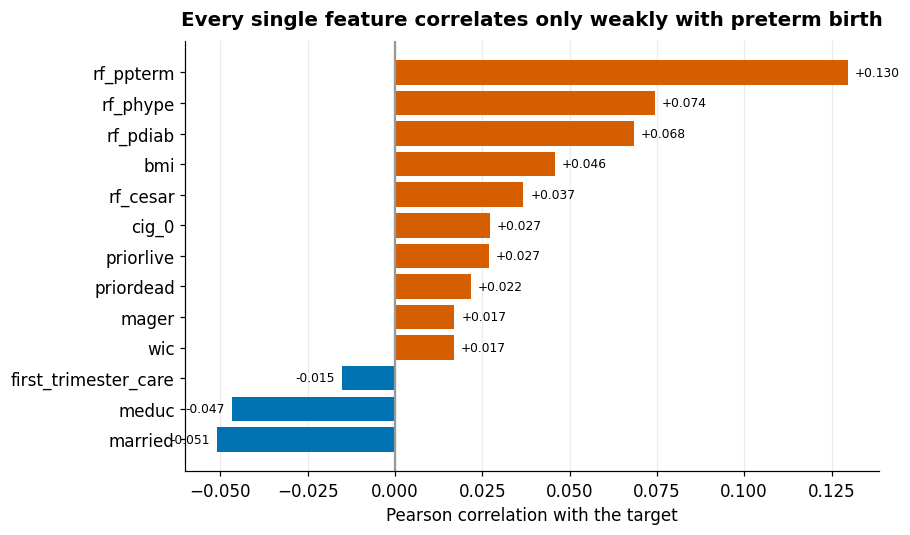

In [27]:
num = ['mager','meduc','bmi','cig_0','priorlive','priordead',
       'rf_ppterm','rf_phype','rf_pdiab','rf_cesar','wic','first_trimester_care','married']
corr = d[num+['preterm']].corr()['preterm'].drop('preterm').sort_values()
fig, ax = plt.subplots(figsize=(8.4, 5))
colors = [PALETTE['blue'] if c < 0 else PALETTE['red'] for c in corr.values]
ax.barh(corr.index, corr.values, color=colors)
for i, v in enumerate(corr.values): ax.text(v + (0.002 if v>=0 else -0.002), i, f'{v:+.3f}', va='center', ha='left' if v>=0 else 'right', fontsize=8)
style(ax, 'Every single feature correlates only weakly with preterm birth', 'Pearson correlation with the target', '')
ax.axvline(0, color=PALETTE['grey']); ax.grid(axis='y'); plt.tight_layout(); plt.show()

In [28]:
# The significance-vs-effect-size trap, made concrete with BMI.
bp = d[d.preterm==1].bmi; bt = d[d.preterm==0].bmi
bp = bp[bp<70]; bt = bt[bt<70]
t, p = stats.ttest_ind(bp, bt, equal_var=False)
print(f'Mean BMI, preterm vs term: {bp.mean():.1f} vs {bt.mean():.1f}  (difference {bp.mean()-bt.mean():.1f})')
print(f'Welch t-test: t = {t:.1f}, p = {p:.1e}  <- wildly significant')
print(f'...yet the actual difference is ~1 BMI unit. With {len(bp)+len(bt):,} rows, p-values detect trivia.')
pooled_sd = np.sqrt(((len(bp)-1)*bp.std()**2 + (len(bt)-1)*bt.std()**2)/(len(bp)+len(bt)-2))
d_cohen = (bp.mean()-bt.mean())/pooled_sd
print(f"Cohen's d for the BMI difference: {d_cohen:.3f}  (well below 0.2, so a small effect, and the "
      "near-zero p-value is detecting a difference too small to act on).")

Mean BMI, preterm vs term: 28.6 vs 27.5  (difference 1.1)
Welch t-test: t = 199.3, p = 0.0e+00  <- wildly significant
...yet the actual difference is ~1 BMI unit. With 24,386,661 rows, p-values detect trivia.
Cohen's d for the BMI difference: 0.160  (well below 0.2, so a small effect, and the near-zero p-value is detecting a difference too small to act on).


The effect-size measures agree with each other. Cohen's d for the BMI gap is about 0.16, which is small by any convention, so the near-zero p-value is detecting a difference no clinician would act on. One more effect-size lens, this time for the categorical race-vs-preterm relationship: Cramer's V, which rescales a chi-square statistic onto a 0-to-1 association scale so it does not balloon with sample size the way chi-square itself does.

In [29]:
ct = pd.crosstab(d.mother_race_ethnicity, d.preterm)
chi2 = stats.chi2_contingency(ct)[0]
n = ct.values.sum(); k = min(ct.shape)
cramers_v = np.sqrt(chi2 / (n * (k - 1)))
print(f"Cramer's V (race vs preterm): {cramers_v:.3f}  (a small association on the 0-1 scale).")

Cramer's V (race vs preterm): 0.057  (a small association on the 0-1 scale).


**This is the whole modeling story in one chart and one test, previewed.** The strongest correlate, prior preterm birth, reaches only about +0.13; everything else is weaker. There is no dominant signal hiding in these fields. And the BMI t-test is a cautionary tale: across tens of millions of rows it returns a p-value near zero for a difference of about 1 BMI unit that no clinician would ever act on. At this sample size, p-values detect trivia. Significance is cheap; effect size is what matters, and the effect sizes here are all small. It strongly suggests that when we get to modeling, the honest performance ceiling will be modest, because the real causes of preterm birth mostly live outside what a birth certificate records.

<a id="takeaways"></a>
## EDA takeaways and the plan from here

What this week's exploration established:

1. Preterm birth is **rare (about 8.6%)** and **weakly correlated** with every recorded field (max correlation about 0.13), which will cap achievable model performance.
2. The strongest legitimate signals are **clinical**: prior preterm birth (about 3.4x risk ratio), the summed medical-risk count, and smoking.
3. The **racial disparity is large (about 4.7 pp), unambiguously significant, and does not close with education**, pointing beyond a simple socioeconomic explanation.
4. With tens of millions of rows, **p-values are not the right lens**; effect sizes are, and they are modest.
5. The **COVID era** barely moves the annual national rate, which is itself a lesson in temporal granularity.

**The plan from here**, now grounded in what we have seen rather than guessed:

- Engineer a leakage-safe feature set, with a tested gate barring at-delivery fields, since the EDA showed the legitimate signals are individually weak and the temptation to reach for leaky fields will be strong.
- Build calibrated baseline and tree models, expecting a modest ceiling, and judge them on AUC and calibration rather than accuracy given the imbalance.
- Turn the disparity finding into a formal fairness audit with confidence intervals, and attempt a decomposition that asks how much of the gap measured factors explain.

That work is for the coming weeks. This week, the data has been acquired, audited, explored, and visualized, and it has already told us something real about equity.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
